In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Reading dataset file
df = pd.read_csv('combined_data_1.txt',header = None, names = ['Cust_Id', 'Rating'], usecols = [0,1])

In [ ]:
#To print the datatype of columns
df.dtypes

,0
Cust_Id,object
Rating,float64


In [ ]:
df.shape

(662488, 2)

In [ ]:
df.head()

,Cust_Id,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0


In [ ]:
#To find the distribution of different ratings in the datset
p = df.groupby('Rating')['Rating'].agg(['count'])
p

,count
Rating,
1.0,31314
2.0,64654
3.0,184810
4.0,232420
5.0,149115


In [ ]:
# get movie count by counting nan values
movie_count = df.isnull().sum()[1]

movie_count

/tmp/ipykernel_1124/3075305399.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  movie_count = df.isnull().sum()[1]


np.int64(175)

In [ ]:
# get customer count
cust_count = df['Cust_Id'].nunique()-movie_count

cust_count

np.int64(244733)

In [ ]:
# get rating count
rating_count = df['Cust_Id'].count() - movie_count

rating_count

np.int64(662313)

/tmp/ipykernel_1124/2440141988.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(p.iloc[i-1][0]/4, i-1, 'Rating {}: {:.0f}%'.format(i, p.iloc[i-1][0]*100 / p.sum()[0]), color = 'white', weight = 'bold')


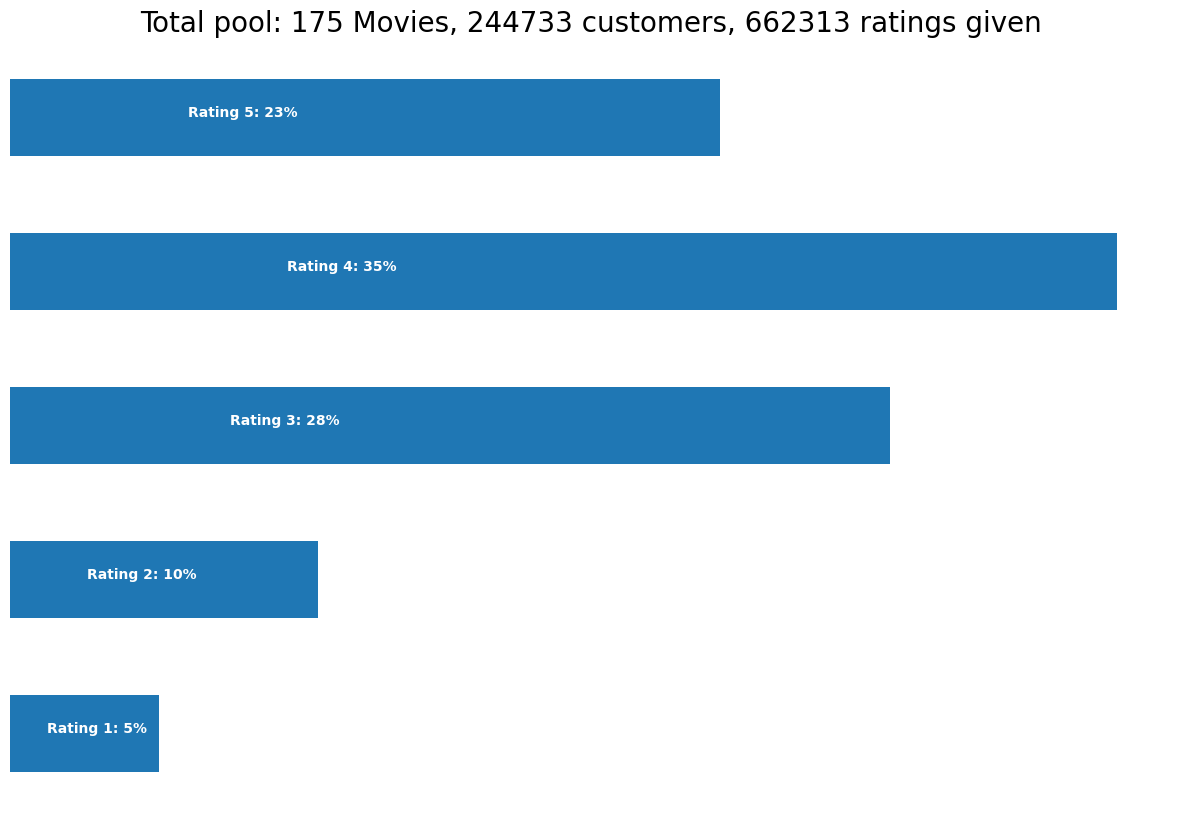

In [ ]:
ax = p.plot(kind = 'barh', legend = False, figsize = (15,10))
plt.title(f'Total pool: {movie_count} Movies, {cust_count} customers, {rating_count} ratings given', fontsize=20)
plt.axis('off')

for i in range(1,6):
    ax.text(p.iloc[i-1][0]/4, i-1, 'Rating {}: {:.0f}%'.format(i, p.iloc[i-1][0]*100 / p.sum()[0]), color = 'white', weight = 'bold')

###
To create a numpy array containing movie ids corresponding to the rows in the 'ratings' dataset

In [ ]:
# To count all the 'nan' values in the Ratings column in the 'ratings' dataset
df_nan = pd.DataFrame(pd.isnull(df.Rating), )

df_nan.head()

,Rating
0,True
1,False
2,False
3,False
4,False


In [ ]:
# To store the index of all the rows containing 'nan' values
df_nan = df_nan[df_nan['Rating'] == True]


df_nan.shape

(175, 1)

In [ ]:
# To reset the index of the dataframe
df_nan = df_nan.reset_index()

df_nan.head()

,index,Rating
0,0,True
1,548,True
2,694,True
3,2707,True
4,2850,True


In [ ]:
#To create a numpy array containing movie ids according the 'ratings' dataset

movie_np = []
movie_id = 1

for i,j in zip(df_nan['index'][1:],df_nan['index'][:-1]):
    # numpy approach
    temp = np.full((1,i-j-1), movie_id)
    movie_np = np.append(movie_np, temp)
    movie_id += 1

# Account for last record and corresponding length
# numpy approach
last_record = np.full((1,len(df) - df_nan.iloc[-1, 0] - 1),movie_id)
movie_np = np.append(movie_np, last_record)

print(f'Movie numpy: {movie_np}')
print(f'Length: {len(movie_np)}')

Movie numpy: [  1.   1.   1. ... 175. 175. 175.]
Length: 662313


In [ ]:
#To append the above created array to the datset after removing the 'nan' rows
dataset = df[pd.notnull(df['Rating'])]

dataset['Movie_Id'] = movie_np.astype(int)
dataset['Cust_Id'] =dataset['Cust_Id'].astype(int)
print('-Dataset examples-')
dataset.head()

-Dataset examples-


/tmp/ipykernel_1124/2432194216.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset['Movie_Id'] = movie_np.astype(int)
/tmp/ipykernel_1124/2432194216.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset['Cust_Id'] =dataset['Cust_Id'].astype(int)


,Cust_Id,Rating,Movie_Id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1


###Data Cleaning

In [ ]:
f = ['count','mean']

In [ ]:
#To create a list of all the movies rated less often(only include top 30% rated movies)
dataset_movie_summary = dataset.groupby('Movie_Id')['Rating'].agg(f)

dataset_movie_summary.index = dataset_movie_summary.index.map(int)

movie_benchmark = round(dataset_movie_summary['count'].quantile(0.7),0)

drop_movie_list = dataset_movie_summary[dataset_movie_summary['count'] < movie_benchmark].index

print('Movie minimum times of review: {}'.format(movie_benchmark))

Movie minimum times of review: 1241.0


In [ ]:
#To create a list of all the inactive users(users who rate less often)
dataset_cust_summary = dataset.groupby('Cust_Id')['Rating'].agg(f)
dataset_cust_summary.index = dataset_cust_summary.index.map(int)
cust_benchmark = round(dataset_cust_summary['count'].quantile(0.7),0)
drop_cust_list = dataset_cust_summary[dataset_cust_summary['count'] < cust_benchmark].index

print(f'Customer minimum times of review: {cust_benchmark}')

Customer minimum times of review: 3.0


In [ ]:
print(f'Original Shape: {dataset.shape}')

Original Shape: (662313, 3)


In [ ]:
dataset = dataset[~dataset['Movie_Id'].isin(drop_movie_list)]
dataset = dataset[~dataset['Cust_Id'].isin(drop_cust_list)]
print('After Trim Shape: {}'.format(dataset.shape))

After Trim Shape: (416461, 3)


In [ ]:
print('-Data Examples-')
dataset.head()

-Data Examples-


,Cust_Id,Rating,Movie_Id
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
700,656399,4.0,3


###
Create ratings matrix for 'ratings' matrix with Rows = userId, Columns = movieId

In [ ]:
df_p = pd.pivot_table(dataset,values='Rating',index='Cust_Id',columns='Movie_Id')

print(df_p.shape)

(86998, 53)


In [ ]:
df_p.head()

Movie_Id,3,8,16,17,18,24,26,28,30,32,...,148,152,156,165,166,167,168,171,173,175
Cust_Id,,,,,,,,,,,,,,,,,,,,,
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,5.0
7,NaN,5.0,NaN,NaN,NaN,NaN,NaN,4.0,5.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0
79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
87,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,5.0
97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,3.0


###
To load the movie_titles dataset

In [ ]:
df_title = pd.read_csv('/content/movie_titles.csv', encoding = "ISO-8859-1", header = None, names = ['Movie_Id', 'Year', 'Name'],on_bad_lines='skip')

df_title.set_index('Movie_Id', inplace = True)

print (df_title.head(10))

            Year                          Name
Movie_Id                                      
1         2003.0               Dinosaur Planet
2         2004.0    Isle of Man TT 2004 Review
3         1997.0                     Character
4         1994.0  Paula Abdul's Get Up & Dance
5         2004.0      The Rise and Fall of ECW
6         1997.0                          Sick
7         1992.0                         8 Man
8         2004.0    What the #$*! Do We Know!?
9         1991.0      Class of Nuke 'Em High 2
10        2001.0                       Fighter


In [ ]:
# Import libraries
from sklearn.decomposition import TruncatedSVD

# 1. Create the User-Item Matrix
# This pivots your 'dataset' into a grid where rows = Users and columns = Movies.
# We fill NaN with 0 because SVD needs a complete matrix.
df_p = dataset.pivot(index='Cust_Id', columns='Movie_Id', values='Rating').fillna(0)

# 2. Initialize and Fit the SVD Model
# n_components is the number of 'latent factors' (hidden genres/styles)
# It must be less than or equal to the number of features (columns) in df_p
svd = TruncatedSVD(n_components=df_p.shape[1] - 1, random_state=42)
matrix_decomposed = svd.fit_transform(df_p)

# 3. Generate Predicted Ratings
# This step 'reconstructs' the matrix, predicting what a user would rate a movie they haven't seen.
weights = svd.components_
predicted_ratings = np.dot(matrix_decomposed, weights)

# Convert to a DataFrame for easy lookup
preds_df = pd.DataFrame(predicted_ratings, columns=df_p.columns, index=df_p.index)

print("SVD Matrix Factorization complete. Shape:", preds_df.shape)

SVD Matrix Factorization complete. Shape: (86998, 53)


In [ ]:
# Combine ratings with movie titles
movie_stats = dataset.groupby('Movie_Id')['Rating'].agg(['count', 'mean'])
movie_stats = movie_stats.join(df_title['Name'], on='Movie_Id')

# Popular: Most number of ratings
popular_movies = movie_stats.sort_values(by='count', ascending=False).head(10)

# Liked: Best average rating (filtered for movies with at least 500 reviews)
liked_movies = movie_stats[movie_stats['count'] > 500].sort_values(by='mean', ascending=False).head(10)

print("Top 5 Most Popular Movies:\n", popular_movies[['Name', 'count']])
print("\nTop 5 Best Liked Movies:\n", liked_movies[['Name', 'mean']])

Top 5 Most Popular Movies:
                                 Name  count
Movie_Id                                   
30            Something's Gotta Give  57682
175                   Reservoir Dogs  45751
143                         The Game  30477
28                   Lilo and Stitch  27324
111              Duplex (Widescreen)  20544
148                   Sweet November  17698
118       Rambo: First Blood Part II  16003
83                          Silkwood  15097
58                       Dragonheart  14737
108                          Spartan  13852

Top 5 Best Liked Movies:
                                                        Name      mean
Movie_Id                                                             
68                                              Invader Zim  4.109643
33                           Aqua Teen Hunger Force: Vol. 1  4.107649
32        ABC Primetime: Mel Gibson's The Passion of the...  4.074848
76                                    I Love Lucy: Season 2  4.0629

In [ ]:
def recommend_movies(user_id, num_recommendations=5):
    # Get the user's predicted ratings row
    user_predictions = preds_df.loc[user_id]

    # Sort by highest predicted score and get the top Movie_Ids
    top_ids = user_predictions.sort_values(ascending=False).head(num_recommendations).index

    # Return titles from our movie_title dataframe
    return df_title.loc[top_ids]['Name']

# Example: Get top 5 picks for user 712664
print(f"Top Recommendations for User 712664:\n{recommend_movies(712664)}")

Top Recommendations for User 712664:
Movie_Id
3                       Character
175                Reservoir Dogs
79                    The Killing
125                    Nighthawks
118    Rambo: First Blood Part II
Name: Name, dtype: object


In [ ]:
# Calculate average rating per genre/movie to find the 'Worst'
worst_movies = movie_stats[movie_stats['count'] > 500].sort_values(by='mean', ascending=True).head(5)

print("Movies with the Lowest User Satisfaction (Worst Ratings):\n", worst_movies[['Name', 'mean']])

Movies with the Lowest User Satisfaction (Worst Ratings):
                         Name      mean
Movie_Id                              
127             Fatal Beauty  2.626432
26           Never Die Alone  2.740152
77                     Congo  2.824286
78        Jingle All the Way  2.875941
17                 7 Seconds  2.904417
